# 05 - A/B test on SIMULATED data

> ## SIMULATED DATA
> The GA4 sample contains **no randomized experiment**. Everything in this notebook is generated by a random number generator with a fixed seed. It demonstrates how an experiment would be **designed and analysed**. It is **not evidence** that any change improved the Google Merchandise Store.

**Scenario.** The funnel analysis (notebook 03) points at the checkout steps. A product manager proposes a simplified one-page checkout.

**Plan written before looking at any results**

| Item | Decision |
|---|---|
| Hypothesis | A simplified checkout increases purchase conversion among users who begin checkout |
| Eligibility | A user enters the experiment the first time they fire `begin_checkout` |
| Randomization unit | User, 50 / 50 control vs treatment |
| Primary metric | Purchase conversion per randomized eligible user |
| Guardrail metric | Revenue per randomized user must not fall |
| Baseline rate (assumption) | 40% |
| Minimum detectable effect | +3 percentage points (absolute) |
| Significance level, power | alpha = 0.05 (two-sided), power = 0.80 |
| Stopping rule | Analyse once, when the planned sample size is reached. No peeking |

In [1]:
# --- Setup: run this cell first ---
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "productpulse").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from productpulse import data, metrics, charts

charts.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(data.data_banner())

Real BigQuery export loaded from: C:\Users\Padmashree\OneDrive\Desktop\ProductPulse-AI\ProductPulse-AI\data\exports


## 1. Sample size, decided in advance

In [2]:
BASELINE = 0.40      # assumed control conversion among users who begin checkout
MDE = 0.03           # smallest absolute lift worth detecting
ALPHA, POWER = 0.05, 0.80
SEED = 42

n_per_group = metrics.sample_size_two_proportions(BASELINE, MDE, ALPHA, POWER)
print(f"Required sample size: {n_per_group:,} users per group ({2 * n_per_group:,} in total)")

for mde in [0.01, 0.02, 0.03, 0.05]:
    print(f"  MDE {mde:+.0%} -> {metrics.sample_size_two_proportions(BASELINE, mde, ALPHA, POWER):>7,} users per group")

Required sample size: 4,234 users per group (8,468 in total)
  MDE +1% ->  37,827 users per group
  MDE +2% ->   9,493 users per group
  MDE +3% ->   4,234 users per group
  MDE +5% ->   1,534 users per group


Halving the detectable effect roughly quadruples the sample. This is why the MDE must be a business decision made before the test.

## 2. Generate the simulated experiment\nThe simulation is given a true effect of +3 points. A real analyst would not know this; it is stated here so the result can be checked against the truth.

In [3]:
rng = np.random.default_rng(SEED)
TRUE_LIFT = 0.03                      # known only because this is a simulation
n_total = 2 * n_per_group

sim = pd.DataFrame({
    "user_id": [f"SIM{i:06d}" for i in range(n_total)],
    "group": rng.choice(["control", "treatment"], size=n_total),      # independent coin flip per user
})
p = np.where(sim["group"] == "treatment", BASELINE + TRUE_LIFT, BASELINE)
sim["purchased"] = (rng.random(n_total) < p).astype(int)
order_value = rng.lognormal(mean=3.9, sigma=0.6, size=n_total).round(2)   # same distribution in both groups
sim["revenue_usd"] = np.where(sim["purchased"] == 1, order_value, 0.0)

out_dir = data.ROOT / "data" / "simulated"
out_dir.mkdir(parents=True, exist_ok=True)
sim.to_csv(out_dir / "SIMULATED_checkout_ab_test.csv", index=False)
print("Saved data/simulated/SIMULATED_checkout_ab_test.csv")
display(sim.head())

Saved data/simulated/SIMULATED_checkout_ab_test.csv


,user_id,group,purchased,revenue_usd
0,SIM000000,control,1,32.3800
1,SIM000001,treatment,1,26.6300
2,SIM000002,treatment,1,47.6100
3,SIM000003,control,0,0.0000
4,SIM000004,control,0,0.0000


## 3. Check the randomization first (sample-ratio mismatch)\nIf the split is far from 50 / 50, the assignment is broken and the result cannot be trusted, whatever the p-value says.

In [4]:
summary = sim.groupby("group").agg(users=("user_id", "size"), purchasers=("purchased", "sum"),
                                   revenue_usd=("revenue_usd", "sum"))
summary["conversion"] = summary["purchasers"] / summary["users"]
summary["revenue_per_user"] = summary["revenue_usd"] / summary["users"]
display(summary.style.format({"users": "{:,.0f}", "purchasers": "{:,.0f}", "revenue_usd": "{:,.2f}",
                              "conversion": "{:.2%}", "revenue_per_user": "{:.2f}"}))

n_c, n_t = int(summary.loc["control", "users"]), int(summary.loc["treatment", "users"])
srm = metrics.sample_ratio_mismatch(n_c, n_t)
print(f"Split: control {n_c:,} / treatment {n_t:,}. SRM chi-square p = {srm['p_value']:.3f} -> "
      f"{'PROBLEM: sample-ratio mismatch' if srm['srm_detected'] else 'no sample-ratio mismatch detected'}")

,users,purchasers,revenue_usd,conversion,revenue_per_user
group,,,,,
control,"4,301","1,775","106,143.59",41.27%,24.68
treatment,"4,167","1,786","107,199.50",42.86%,25.73


Split: control 4,301 / treatment 4,167. SRM chi-square p = 0.145 -> no sample-ratio mismatch detected


## 4. Primary metric: purchase conversion

Control   : 41.27%  (1,775 / 4,301)
Treatment : 42.86%  (1,786 / 4,167)
Absolute lift: +1.59% points  (95% CI -0.51% to +3.69%)
Relative lift: +3.9%
z = 1.48, p-value = 0.1381

Statistically significant at alpha = 0.05: no
Whole confidence interval above zero: no
Interval includes the planned MDE of +3%: yes


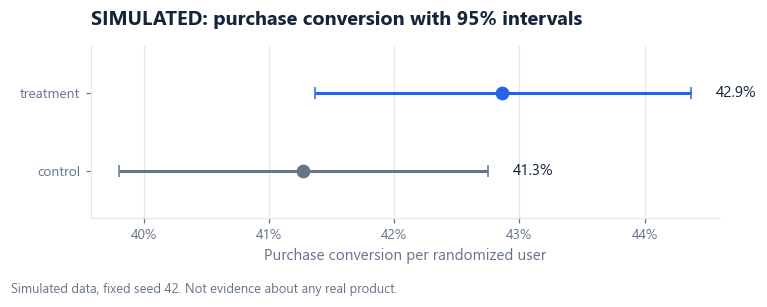

In [5]:
x_c, x_t = int(summary.loc["control", "purchasers"]), int(summary.loc["treatment", "purchasers"])
res = metrics.two_proportion_test(x_c, n_c, x_t, n_t, alpha=ALPHA)

print(f"Control   : {res['control_rate']:.2%}  ({x_c:,} / {n_c:,})")
print(f"Treatment : {res['treatment_rate']:.2%}  ({x_t:,} / {n_t:,})")
print(f"Absolute lift: {res['absolute_lift']:+.2%} points  (95% CI {res['ci_low']:+.2%} to {res['ci_high']:+.2%})")
print(f"Relative lift: {res['relative_lift']:+.1%}")
print(f"z = {res['z']:.2f}, p-value = {res['p_value']:.4f}")

significant = res["p_value"] < ALPHA
practical = res["ci_low"] > 0
print()
print("Statistically significant at alpha = 0.05:", "yes" if significant else "no")
print("Whole confidence interval above zero:", "yes" if practical else "no")
print(f"Interval includes the planned MDE of {MDE:+.0%}:", "yes" if res["ci_low"] <= MDE <= res["ci_high"] else "no")

fig, ax = plt.subplots(figsize=(7, 2.6))
groups = ["control", "treatment"]
rates = [res["control_rate"], res["treatment_rate"]]
cis = [metrics.wilson_interval(x_c, n_c), metrics.wilson_interval(x_t, n_t)]
for i, (g, r, (lo, hi)) in enumerate(zip(groups, rates, cis)):
    colour = charts.MUTED if g == "control" else charts.BLUE
    ax.errorbar(r, i, xerr=[[r - lo], [hi - r]], fmt="o", color=colour, capsize=4, markersize=8, linewidth=2)
    ax.text(hi + 0.002, i, f"{r:.1%}", va="center", fontsize=10, color=charts.NAVY)
ax.set_yticks([0, 1]); ax.set_yticklabels(groups); ax.set_ylim(-0.6, 1.6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("SIMULATED: purchase conversion with 95% intervals")
ax.set_xlabel("Purchase conversion per randomized user")
ax.grid(axis="y", visible=False)
charts.note(fig, "Simulated data, fixed seed 42. Not evidence about any real product.")
(data.ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(data.ROOT / "reports" / "figures" / "SIMULATED_ab_test_conversion.png")
plt.show()

## 5. Guardrail: revenue per randomized user\nRevenue per user is skewed (most users spend 0), so Welch's t-test is backed up with a bootstrap interval.

In [6]:
rev_c = sim.loc[sim["group"] == "control", "revenue_usd"].to_numpy()
rev_t = sim.loc[sim["group"] == "treatment", "revenue_usd"].to_numpy()
t_stat, p_rev = stats.ttest_ind(rev_t, rev_c, equal_var=False)
diff_rev = rev_t.mean() - rev_c.mean()

boot_rng = np.random.default_rng(SEED + 1)
boot = [boot_rng.choice(rev_t, len(rev_t)).mean() - boot_rng.choice(rev_c, len(rev_c)).mean() for _ in range(2000)]
b_lo, b_hi = np.percentile(boot, [2.5, 97.5])

print(f"Revenue per user: control ${rev_c.mean():.2f}, treatment ${rev_t.mean():.2f}")
print(f"Difference: ${diff_rev:+.2f} per user (bootstrap 95% CI ${b_lo:+.2f} to ${b_hi:+.2f}); Welch t-test p = {p_rev:.3f}")
if b_hi < 0:
    print("Guardrail FAILED: revenue per user is lower in treatment (whole interval below zero).")
elif b_lo < 0:
    print("Guardrail: no evidence of harm, but the interval still includes a small loss.")
else:
    print("Guardrail PASSED: revenue per user is higher in treatment (whole interval above zero).")

Revenue per user: control $24.68, treatment $25.73
Difference: $+1.05 per user (bootstrap 95% CI $-0.62 to $+2.61); Welch t-test p = 0.218
Guardrail: no evidence of harm, but the interval still includes a small loss.


## 6. Reading the result

**What a p-value means.** If the two checkouts truly performed the same, the p-value is the probability of seeing a gap at least this large from random assignment alone. It is *not* the probability that the treatment works, and it says nothing about how large the benefit is. The confidence interval does that.

**The result of this simulated run (seed 42).** Control converted 41.27% (1,775 / 4,301) and treatment 42.86% (1,786 / 4,167): a lift of +1.59 points, 95% CI -0.51 to +3.69, p = 0.138. The split passed the sample-ratio check (p = 0.145). Revenue per user was $24.68 vs $25.73, with an interval that includes zero. If your printed numbers differ (for example with another NumPy version), update this paragraph to match.

**What would be decided.** The rule was fixed in advance: ship only if the primary metric is significant, the interval excludes zero and the guardrail is not harmed. Here the result is **inconclusive**: the interval includes zero, so the test did not show that the new checkout is better. It did not show that it is worse or useless either, because the interval also contains the planned +3 points. The honest call is "do not ship on this evidence; extend or rerun with a larger sample".

**Why this is a useful outcome to show.** The simulation was built with a true lift of +3 points, and a correctly designed test still missed it. That is what 80% power means: one properly sized test in five fails to detect a real effect of the planned size. "Not significant" is not the same as "no effect".

**Threats to validity a real test must handle**
- **Novelty effect**: a new design can win for a week because it is new. Run for at least two full weeks and compare week 1 with week 2.
- **Sample-ratio mismatch**: checked in section 3; a mismatch invalidates the test.
- **Peeking**: checking daily and stopping at the first significant result inflates false positives. Analyse once, at the planned sample size.
- **Multiple testing**: one primary metric only. Every extra metric or segment cut raises the chance of a false win.
- **Duration and seasonality**: this dataset covers the holiday period; a test run then may not generalise to February.

**Why none of this is evidence of impact.** The effect was typed into the simulation (`TRUE_LIFT = 0.03`). The notebook demonstrates the method and the reasoning, nothing more. A memo version of this plan is in `reports/experiment_memo.md`.